# 01 - Data quality audit and cleaning

**Question.** How messy was the raw data, what did cleaning change, and can the cleaned
numbers be trusted?

**Method.** Compare raw and cleaned row counts, profile missing values, walk through the
cleaning log written by `src/clean.py`, explain the change in revenue step by step, and
reconcile cleaned order totals against the independent payment records.

The data is synthetic (see the README). Because the generator logged every issue it
injected, this notebook can also check that cleaning caught all of them, which is not
possible with real data.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().resolve().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import metrics, plots
from src.common import load_config, project_path

cfg = load_config()
conn = metrics.open_db(cfg)
FIGURES = project_path(cfg["paths"]["figures_dir"])
pd.set_option("display.float_format", "{:,.2f}".format)
plots.apply_style()
from src.common import load_tables

## Row counts before and after cleaning

In [2]:
raw = load_tables(project_path(cfg["paths"]["raw_dir"]))
clean = load_tables(project_path(cfg["paths"]["processed_dir"]))
row_counts = pd.DataFrame({
    "raw_rows": {name: len(df) for name, df in raw.items()},
    "clean_rows": {name: len(df) for name, df in clean.items()},
})
row_counts["removed"] = row_counts["raw_rows"] - row_counts["clean_rows"]
row_counts["removed_pct"] = row_counts["removed"] / row_counts["raw_rows"] * 100
row_counts

,raw_rows,clean_rows,removed,removed_pct
customers,1500,1500,0,0.00
categories,10,10,0,0.00
products,300,300,0,0.00
orders,4040,3975,65,1.61
order_items,8762,8685,77,0.88
payments,4000,3975,25,0.62
returns,676,673,3,0.44


## Missing values in the raw data

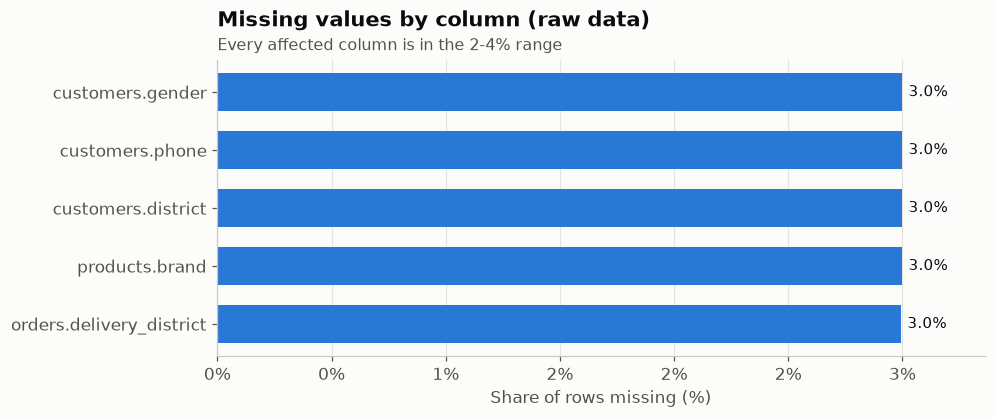

In [3]:
missing = pd.concat({name: df.isna().mean() for name, df in raw.items()}).rename("missing_share")
missing = missing[missing > 0].sort_values(ascending=False)
missing.index = [f"{table}.{column}" for table, column in missing.index]

fig, ax = plots.new_figure(9, 3.5)
plots.bar_chart(ax, list(missing.index), missing.to_numpy(), value_format="{:.1%}")
plots.format_axis(ax, "x", "pct")
plots.set_titles(ax, "Missing values by column (raw data)", "Every affected column is in the 2-4% range")
ax.set_xlabel("Share of rows missing (%)")
plots.save_figure(fig, FIGURES / "01_missing_values.png")
plt.show()

Are the gaps random? The checks below compare missing rates across groups: one-order
buyers against repeat buyers for customer districts, and orders before and after January
2024 for delivery districts. Gaps that cluster in particular groups would bias any
analysis that simply drops incomplete rows.

In [4]:
summary = metrics.run_query(conn, "customer_summary")
raw_district_missing = raw["customers"].set_index("customer_id")["district"].isna()
buyer_group = summary["orders"].gt(1).map({True: "repeat buyer", False: "one-order buyer"})
by_buyer = summary["customer_id"].map(raw_district_missing).groupby(buyer_group).mean().rename("district_missing")

order_dates = clean["orders"].set_index("order_id")["order_date"]
raw_orders = raw["orders"].drop_duplicates("order_id")
order_period = pd.to_datetime(raw_orders["order_id"].map(order_dates)).lt("2024-01-01").map(
    {True: "before 2024", False: "2024 onwards"})
by_period = raw_orders["delivery_district"].isna().groupby(order_period).mean().rename("delivery_district_missing")
display(by_buyer.to_frame().style.format("{:.1%}"), by_period.to_frame().style.format("{:.1%}"))

,district_missing
orders,
one-order buyer,3.5%
repeat buyer,2.4%


,delivery_district_missing
order_id,
2024 onwards,2.9%
before 2024,3.2%


## Cleaning steps

Each step in `src/clean.py` logs rows before and after. The decisions:

| Issue | Decision | Why |
|---|---|---|
| Exact duplicate orders | drop | double-counts revenue |
| Unparseable or out-of-window order dates | drop order and its lines | no reliable date to place it in time |
| Unknown customer or product id | drop | cannot be attributed to a customer or category |
| Negative quantity | absolute value | returns live in their own table, so a negative is a sign error |
| Unit price over 10x list price | replace with list price | a lost decimal point at data entry |
| Text casing, whitespace, old spellings, typos | map to canonical names | exact match, then known alias, then fuzzy match |
| Missing delivery district | customer's home district | 90% of orders ship home |
| Missing customer district, gender, brand | label "Unknown" | keeps the gap visible instead of guessing |

In [5]:
log = pd.read_csv(project_path(cfg["paths"]["processed_dir"]) / "cleaning_log.csv")
log[["table", "step", "rows_before", "rows_after", "rows_changed"]]

,table,step,rows_before,rows_after,rows_changed
0,customers,standardize division,1500,1500,103
1,customers,standardize district,1500,1500,101
2,customers,parse signup_date (0 unparseable),1500,1500,225
3,customers,fill missing district with 'Unknown',1500,1500,45
4,customers,fill missing gender with 'Unknown',1500,1500,45
5,customers,keep missing phone as null (not used),1500,1500,45
6,products,standardize category_name,300,300,21
7,products,fill missing brand with 'Unknown',300,300,9
8,orders,drop duplicate orders,4040,4000,40
9,orders,parse order_date (1 unparseable),4000,4000,601


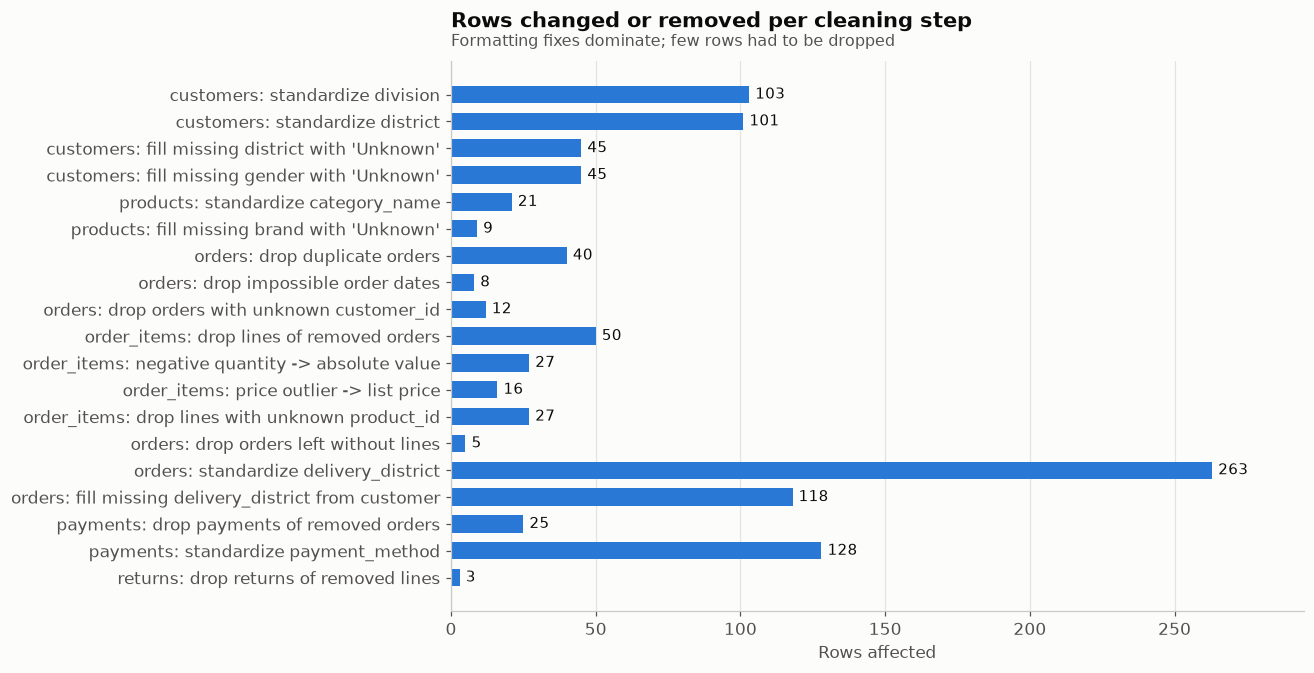

In [6]:
changed = log[(log["rows_changed"] > 0) & ~log["step"].str.startswith(("parse", "keep"))]
labels = (changed["table"] + ": " + changed["step"]).tolist()

fig, ax = plots.new_figure(10, 6.5)
plots.bar_chart(ax, labels, changed["rows_changed"].to_numpy())
plots.set_titles(ax, "Rows changed or removed per cleaning step", "Formatting fixes dominate; few rows had to be dropped")
ax.set_xlabel("Rows affected")
plots.save_figure(fig, FIGURES / "01_cleaning_steps.png")
plt.show()

## Revenue bridge: raw to clean

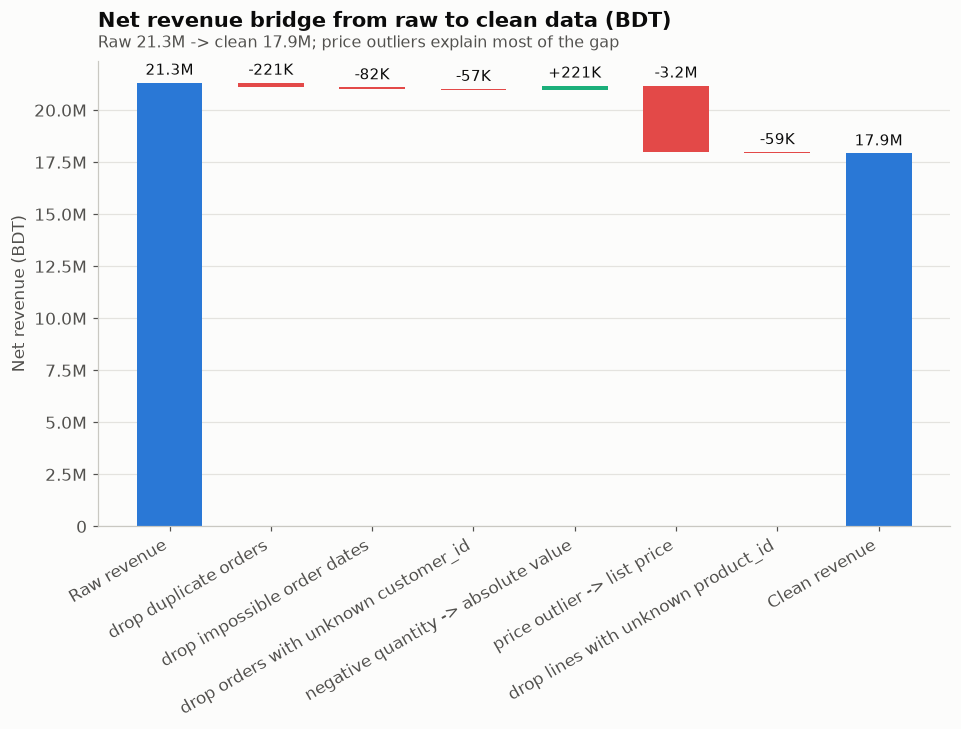

,revenue_change_bdt
step,
drop duplicate orders,"-220,648.00"
drop impossible order dates,"-82,026.50"
drop orders with unknown customer_id,"-57,001.00"
negative quantity -> absolute value,"220,969.00"
price outlier -> list price,"-3,198,294.00"
drop lines with unknown product_id,"-58,761.50"


In [7]:
revenue_steps = log.dropna(subset=["revenue_before"]).copy()
revenue_steps["change"] = revenue_steps["revenue_after"] - revenue_steps["revenue_before"]
moves = revenue_steps[revenue_steps["change"].abs() > 0.5].set_index("step")["change"]
raw_revenue = revenue_steps["revenue_before"].iloc[0]
clean_revenue = revenue_steps["revenue_after"].iloc[-1]

fig, ax = plots.new_figure(10, 5.5)
plots.waterfall(ax, "Raw revenue", raw_revenue, moves, "Clean revenue")
plots.set_titles(ax, "Net revenue bridge from raw to clean data (BDT)",
                 f"Raw {plots.bdt(raw_revenue)} -> clean {plots.bdt(clean_revenue)}; price outliers explain most of the gap")
ax.set_ylabel("Net revenue (BDT)")
plots.save_figure(fig, FIGURES / "01_revenue_bridge.png")
plt.show()
moves.to_frame("revenue_change_bdt")

## Did cleaning catch every injected issue?

In [8]:
issues = pd.read_csv(project_path(cfg["paths"]["issue_log"]))
issues.groupby(["table", "issue_type"]).size().unstack(fill_value=0)

issue_type,duplicate_row,impossible_date,missing_value,mixed_date_format,negative_quantity,orphan_fk,price_outlier,text_noise,typo
table,,,,,,,,,
customers,0,0,135,225,0,0,0,148,56
order_items,0,0,0,0,27,27,16,0,0
orders,40,8,120,600,0,12,0,192,72
payments,0,0,0,600,0,0,0,200,0
products,0,0,9,0,0,0,0,15,6
returns,0,0,0,101,0,0,0,0,0


The counts match the cleaning log: 40 duplicates, 8 impossible dates, 12 orders and 27
lines with unknown ids, 27 negative quantities and 16 price outliers. `tests/test_pipeline.py`
checks this row by row against the issue log, so it is enforced on every run, not just
eyeballed here.

## Reconciliation with payments

In [9]:
orders = metrics.run_query(conn, "order_revenue")
payments = pd.read_sql_query("SELECT order_id, amount FROM payments", conn)
check = orders.merge(payments, on="order_id")
check["difference"] = check["net_revenue"] - check["amount"]
matched = check["difference"].abs() <= 0.01
print(f"Delivered orders whose line total matches the payment to the taka: {matched.mean():.1%} ({matched.sum()} of {len(check)})")
print(f"Orders that differ: {(~matched).sum()}; total difference {check.loc[~matched, 'difference'].sum():,.0f} BDT")

Delivered orders whose line total matches the payment to the taka: 99.4% (3881 of 3903)
Orders that differ: 22; total difference -50,329 BDT


The payment system recorded each order's amount independently of the order lines. After
cleaning, 99.4% of delivered orders match their payment exactly. The 22 that differ are
the orders that lost a line with an unknown product id: the customer paid for that line,
but it cannot be attributed to a product or category, so it was removed. This is a known,
quantified gap (about 50K BDT, 0.3% of revenue), not an error.

## Findings

- 1% of order rows were duplicates and about 25 orders (0.6%) had to be dropped. Everything
  else was fixable in place.
- Raw revenue overstated clean revenue by 19% (21.3M vs 17.9M BDT). Almost all of it came
  from 16 order lines whose price was entered at 100x, so a handful of rows can distort
  totals badly.
- Missing values are not fully random. One-order buyers are more likely to have a
  missing district (3.5% vs 2.4% for repeat buyers), and pre-2024 orders slightly more
  likely to miss a delivery district (3.2% vs 2.9%). Rows were therefore labelled or
  filled, never dropped for being incomplete.
- Cleaned revenue reconciles with the payment records for 99.4% of orders. The rest are
  explained by one known step.